# 👶 Cardiotocography (CTG) Fetal Health Classification

### Multi-Class Fetal State Classification
Obstetric clinical guidelines categorize CTG patterns into three distinct clinical states:
- **Class 1: Normal** (Reassuring physiological tracing; intact autonomic nervous system and adequate fetal oxygenation).
- **Class 2: Suspect** (Equivocal tracing; requires close surveillance, maternal repositioning, oxygenation, and potential scalp sampling).
- **Class 3: Pathological** (Critical fetal distress and severe acidosis; necessitates immediate obstetric intervention and emergency operative delivery).

### Dataset Overview
- **Source**: UCI Machine Learning Repository / Kaggle CTG Dataset.
- **Records**: 2,126 patient recordings.
- **Features**: 21 continuous morphological and histogram features derived from CTG signals.
- **Missing Values**: 0 (complete tabular dataset).
- **Challenge**: Significant class imbalance (Normal ~78%, Suspect ~14%, Pathological ~8%). Effective modeling requires sensitivity optimization, particularly for the high-consequence **Pathological** class.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 1. Data Loading and Exploratory Data Analysis (EDA)

In [2]:
data_path = "fetal_health.csv"
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
df.head()

Dataset Shape: 2126 rows, 22 columns
Total Missing Values: 0


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1


,Class Index,Fetal State,Patient Count,Percentage (%)
0,1,Normal,1655,77.85
1,2,Suspect,295,13.88
2,3,Pathological,176,8.28


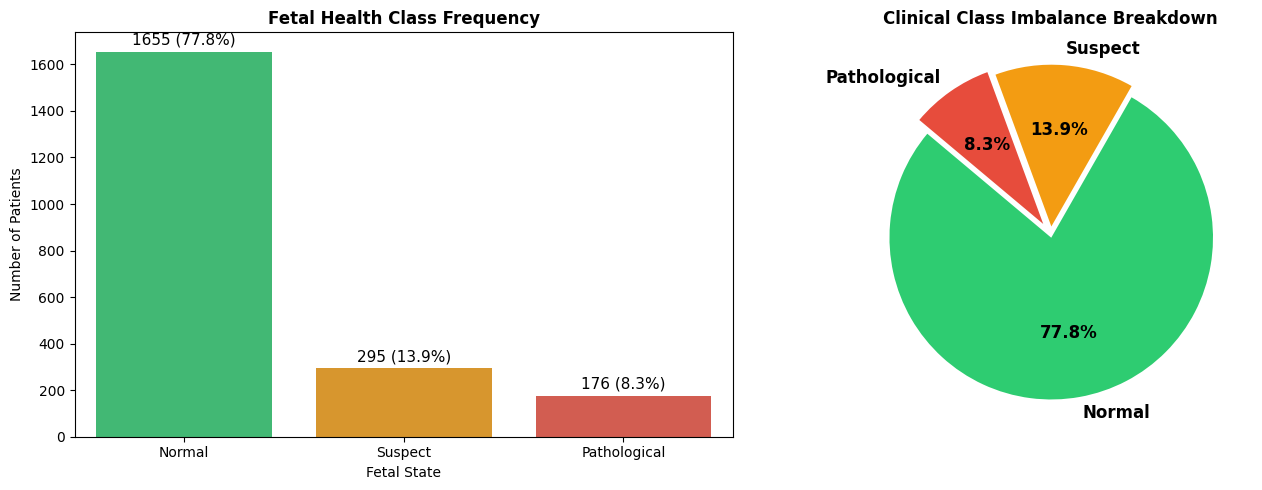

In [3]:
# Target class distribution
class_mapping = {1: "Normal", 2: "Suspect", 3: "Pathological"}
class_counts = df['fetal_health'].value_counts().sort_index()

dist_df = pd.DataFrame({
    'Class Index': class_counts.index,
    'Fetal State': [class_mapping[i] for i in class_counts.index],
    'Patient Count': class_counts.values,
    'Percentage (%)': (class_counts.values / len(df) * 100).round(2)
})
display(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot
colors = ["#2ecc71", "#f39c12", "#e74c3c"]
sns.barplot(
    data=dist_df,
    x='Fetal State',
    y='Patient Count',
    hue='Fetal State',
    palette=colors,
    legend=False,
    ax=axes[0]
)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='baseline', fontsize=11,
                    xytext=(0, 5), textcoords='offset points')
axes[0].set_title("Fetal Health Class Frequency", fontweight='bold')
axes[0].set_ylabel("Number of Patients")

# Pie chart
axes[1].pie(
    dist_df['Patient Count'],
    labels=dist_df['Fetal State'],
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    explode=(0.02, 0.05, 0.08),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[1].set_title("Clinical Class Imbalance Breakdown", fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# Summary statistics of key CTG clinical parameters
key_features = [
    'baseline value',
    'accelerations',
    'fetal_movement',
    'uterine_contractions',
    'prolongued_decelerations',
    'abnormal_short_term_variability',
    'percentage_of_time_with_abnormal_long_term_variability'
]

df[key_features].describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
baseline value,133.303857,9.840844,106.0,133.000000,160.000000
accelerations,0.003170,0.003860,0.0,0.001630,0.019284
fetal_movement,0.009474,0.046670,0.0,0.000000,0.480634
uterine_contractions,0.004357,0.002940,0.0,0.004482,0.014925
prolongued_decelerations,0.000157,0.000580,0.0,0.000000,0.005348
abnormal_short_term_variability,46.990122,17.192814,12.0,49.000000,87.000000
percentage_of_time_with_abnormal_long_term_variability,9.846660,18.396880,0.0,0.000000,91.000000


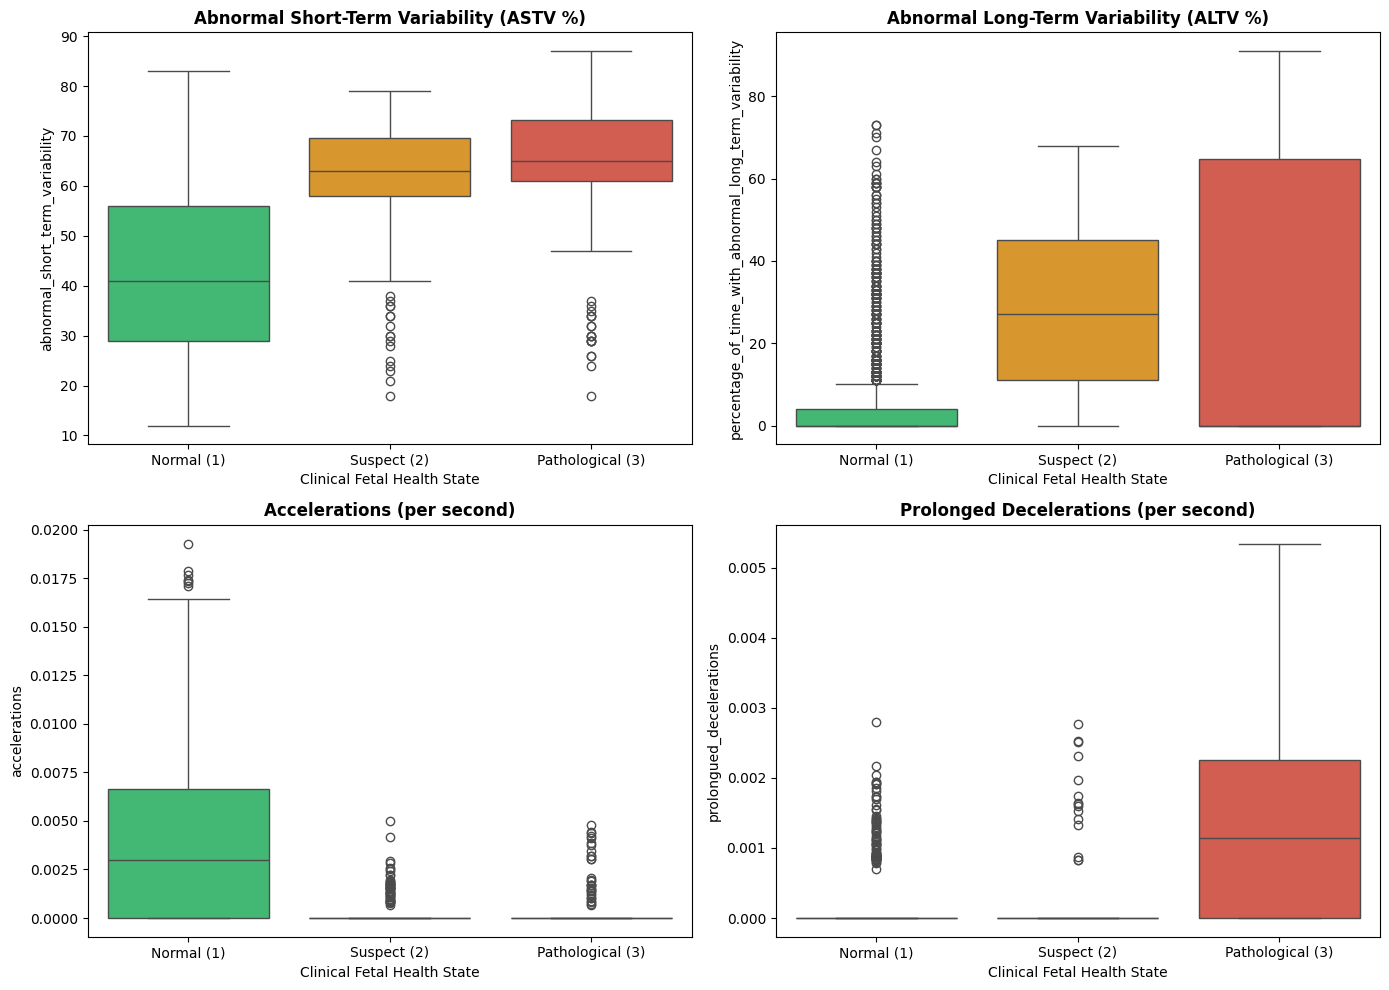

In [5]:
# Distributions of key clinical features across fetal states
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_features = [
    ('abnormal_short_term_variability', 'Abnormal Short-Term Variability (ASTV %)'),
    ('percentage_of_time_with_abnormal_long_term_variability', 'Abnormal Long-Term Variability (ALTV %)'),
    ('accelerations', 'Accelerations (per second)'),
    ('prolongued_decelerations', 'Prolonged Decelerations (per second)')
]

tick_labels = ["Normal (1)", "Suspect (2)", "Pathological (3)"]

for idx, (col, title) in enumerate(plot_features):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(
        data=df,
        x='fetal_health',
        y=col,
        hue='fetal_health',
        palette=colors,
        legend=False,
        ax=ax
    )
    ax.set_xticks(range(len(tick_labels)), labels=tick_labels)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("Clinical Fetal Health State")

plt.tight_layout()
plt.show()

## 2. Feature Matrix Preparation and Stratified Train-Test Split

In [6]:
features = [c for c in df.columns if c != 'fetal_health']
X = df[features]
y = df['fetal_health']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing holdout set: {X_test.shape[0]} samples")
print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 1594 samples
Testing holdout set: 532 samples

Training Class Distribution:
fetal_health
1    0.779
2    0.139
3    0.083
Name: proportion, dtype: float64

Testing Class Distribution:
fetal_health
1    0.778
2    0.139
3    0.083
Name: proportion, dtype: float64


## 3. Class Imbalance Handling via SMOTE
In medical diagnosis, failing to identify a compromised fetus (False Negative on Class 3) is clinically hazardous. 
Because Pathological cases represent only ~8.3% of the cohort, standard models risk optimizing for overall accuracy at the expense of minority class recall.
We apply **Synthetic Minority Over-sampling Technique (SMOTE)** strictly on the training set.

In [7]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Original Training Size: {len(y_train)} samples")
print("Original Class Breakdown:")
print(y_train.value_counts())

print(f"\nResampled Training Size: {len(y_train_res)} samples")
print("Resampled Class Breakdown:")
print(y_train_res.value_counts())

Original Training Size: 1594 samples
Original Class Breakdown:
fetal_health
1    1241
2     221
3     132
Name: count, dtype: int64

Resampled Training Size: 3723 samples
Resampled Class Breakdown:
fetal_health
1    1241
2    1241
3    1241
Name: count, dtype: int64


## 4. Model Training and 5-Fold Stratified GridSearchCV Tuning
We evaluate 3 machine learning models:
1. **Random Forest Classifier**: Non-linear ensemble of decision trees with bagging.
2. **XGBoost Classifier**: Gradient boosted decision trees with regularized objective.
3. **LightGBM Classifier**: Highly efficient leaf-wise gradient boosting.

### Hyperparameter Optimization Strategy:
- **5-Fold Stratified Cross-Validation**: Preserves balanced class ratios across all validation folds.
- **Scoring**: `f1_macro` (unweighted average of F1 across all three classes, giving equal weight to minority detection).
- **Prefix-Free Parameter Grids**: Pure parameter dictionaries passed directly to `GridSearchCV`.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_models = {}
best_hyperparams = {}
cv_scores = {}

# 1. Random Forest Classifier
print("--- Tuning Random Forest ---")
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12, None],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)
rf_grid.fit(X_train_res, y_train_res)
best_models['Random Forest'] = rf_grid.best_estimator_
best_hyperparams['Random Forest'] = rf_grid.best_params_
cv_scores['Random Forest'] = rf_grid.best_score_
print(f"Best RF Params: {rf_grid.best_params_}")
print(f"Best RF 5-Fold Macro F1: {rf_grid.best_score_:.4f}")

# 2. XGBoost Classifier 
print("\n--- Tuning XGBoost ---")
y_train_xgb = y_train_res - 1
xgb_param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1]
}
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='mlogloss'),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)
xgb_grid.fit(X_train_res, y_train_xgb)
best_models['XGBoost'] = xgb_grid.best_estimator_
best_hyperparams['XGBoost'] = xgb_grid.best_params_
cv_scores['XGBoost'] = xgb_grid.best_score_
print(f"Best XGBoost Params: {xgb_grid.best_params_}")
print(f"Best XGBoost 5-Fold Macro F1: {xgb_grid.best_score_:.4f}")

# 3. LightGBM Classifier 
print("\n--- Tuning LightGBM ---")
lgb_param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [5, 8],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}
lgb_grid = GridSearchCV(
    estimator=LGBMClassifier(random_state=42, verbose=-1),
    param_grid=lgb_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)
lgb_grid.fit(X_train_res, y_train_xgb)
best_models['LightGBM'] = lgb_grid.best_estimator_
best_hyperparams['LightGBM'] = lgb_grid.best_params_
cv_scores['LightGBM'] = lgb_grid.best_score_
print(f"Best LightGBM Params: {lgb_grid.best_params_}")
print(f"Best LightGBM 5-Fold Macro F1: {lgb_grid.best_score_:.4f}")

--- Tuning Random Forest ---
Best RF Params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best RF 5-Fold Macro F1: 0.9812

--- Tuning XGBoost ---
Best XGBoost Params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 150}
Best XGBoost 5-Fold Macro F1: 0.9820

--- Tuning LightGBM ---
Best LightGBM Params: {'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 150, 'num_leaves': 31}
Best LightGBM 5-Fold Macro F1: 0.9868


## 5. Models Evaluation 

In [9]:
eval_results = {}
predictions = {}

for name, model in best_models.items():
    if name in ['XGBoost', 'LightGBM']:
        y_pred = model.predict(X_test) + 1
        y_prob = model.predict_proba(X_test)
    else:
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)
        
    predictions[name] = {'y_pred': y_pred, 'y_prob': y_prob}
    
    acc = accuracy_score(y_test, y_pred)
    f1_m = f1_score(y_test, y_pred, average='macro')
    f1_w = f1_score(y_test, y_pred, average='weighted')
    rec_per_class = recall_score(y_test, y_pred, average=None)
    
    eval_results[name] = {
        '5-Fold CV F1-Macro': round(cv_scores[name], 4),
        'Accuracy': round(acc, 4),
        'Macro F1': round(f1_m, 4),
        'Weighted F1': round(f1_w, 4),
        'Normal Sensitivity': round(rec_per_class[0], 4),
        'Suspect Sensitivity': round(rec_per_class[1], 4),
        'Pathological Sensitivity': round(rec_per_class[2], 4)
    }

eval_df = pd.DataFrame(eval_results).T
display(eval_df)

,5-Fold CV F1-Macro,Accuracy,Macro F1,Weighted F1,Normal Sensitivity,Suspect Sensitivity,Pathological Sensitivity
Random Forest,0.9812,0.9305,0.8822,0.9311,0.9565,0.7973,0.9091
XGBoost,0.9820,0.9305,0.8700,0.9290,0.9710,0.7162,0.9091
LightGBM,0.9868,0.9417,0.8895,0.9397,0.9807,0.7162,0.9545


Top Performing Model: LightGBM
Holdout Test Accuracy: 94.2%
Holdout Macro F1: 0.8895
Pathological Sensitivity: 95.5%


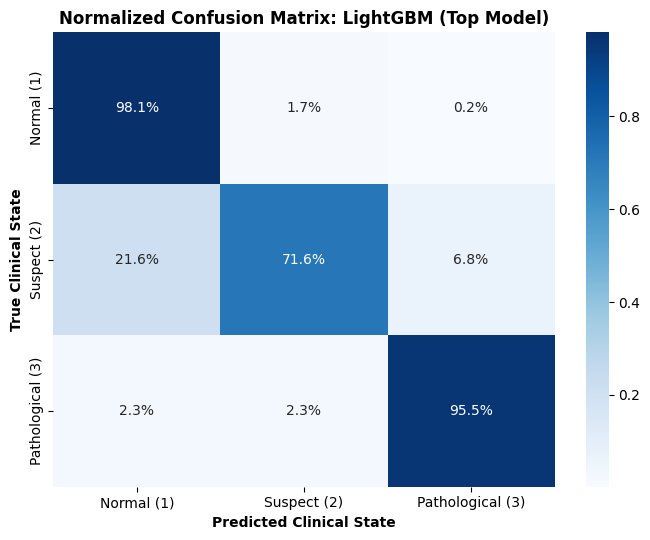

In [10]:
best_model_name = max(eval_results, key=lambda k: eval_results[k]['Macro F1'])
print(f"Top Performing Model: {best_model_name}")
print(f"Holdout Test Accuracy: {eval_results[best_model_name]['Accuracy']:.1%}")
print(f"Holdout Macro F1: {eval_results[best_model_name]['Macro F1']:.4f}")
print(f"Pathological Sensitivity: {eval_results[best_model_name]['Pathological Sensitivity']:.1%}")

target_names = ["Normal (1)", "Suspect (2)", "Pathological (3)"]
cm = confusion_matrix(y_test, predictions[best_model_name]['y_pred'], normalize='true')

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    cbar=True
)
plt.title(f"Normalized Confusion Matrix: {best_model_name} (Top Model)", fontweight='bold', fontsize=12)
plt.ylabel("True Clinical State", fontweight='bold')
plt.xlabel("Predicted Clinical State", fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Clinical Feature Importance Rankings

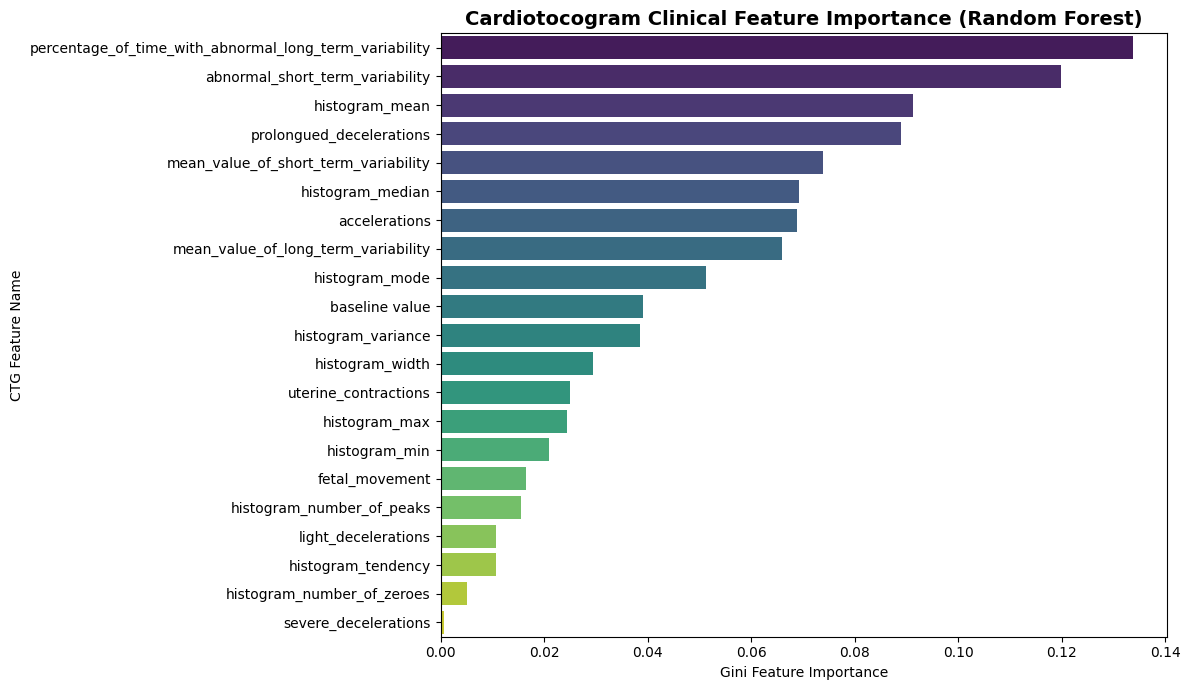

In [11]:
# Extract feature importances from Random Forest
rf_model = best_models['Random Forest']
importances = rf_model.feature_importances_

fi_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=fi_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette="viridis",
    legend=False
)
plt.title("Cardiotocogram Clinical Feature Importance (Random Forest)", fontweight='bold', fontsize=14)
plt.xlabel("Gini Feature Importance")
plt.ylabel("CTG Feature Name")
plt.tight_layout()
plt.show()

## 7. Export Production Model Artifact Bundle


In [12]:
bundle = {
    'models': best_models,
    'best_params': best_hyperparams,
    'eval_results': eval_results,
    'features': features,
    'feature_importance': fi_df.to_dict('records'),
    'feature_summary': df[features].describe().T[['mean', 'std', 'min', '50%', 'max']].to_dict('index')
}

export_path = "fetal_health_bundle.joblib"
joblib.dump(bundle, export_path)
print(f"Production bundle saved successfully to '{export_path}' ({os.path.getsize(export_path) / (1024*1024):.2f} MB)")

Production bundle saved successfully to 'fetal_health_bundle.joblib' (8.05 MB)
